# House Rent Analysis - Machine Learning Models
**Coursework / Assignment Notebook**

This notebook applies all core Machine Learning models learned in the course to the **House Rent Dataset**, properly categorized by their nature:
1. **Regression Models** (Predicting the continuous target `Rent`):
   - **Linear Regression**
   - **K-Nearest Neighbors Regressor (KNN)**
   - **Support Vector Machine Regressor (SVR)**
2. **Classification Models** (Predicting the categorical target `Rent_Category` - High Rent vs. Low Rent):
   - **Logistic Regression**
   - **K-Nearest Neighbors Classifier (KNN)**
   - **Naive Bayes (GaussianNB)**
   - **Support Vector Machine Classifier (SVC)**

---


## 1. Import Libraries
We import essential libraries for data handling, visualization, and machine learning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)



## 2. Load and Explore Dataset
Let us load the dataset and inspect its structure, columns, and sample records.

In [2]:

df = pd.read_csv('House_Rent_Dataset.csv')

print(df.shape)
df.head()

(4746, 12)


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [ ]:
df.info()

In [3]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


## 3. Data Cleaning and Preprocessing
Handling missing values and encoding categorical features.

In [4]:

print(df.isnull().sum())

Posted On            0
BHK                  0
Rent                 5
Size                 8
Floor                0
Area Type            7
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             4
Point of Contact     0
dtype: int64


In [8]:

df['Rent'] = df['Rent'].fillna(df['Rent'].median())
df['Size'] = df['Size'].fillna(df['Size'].median())
df['Bathroom'] = df['Bathroom'].fillna(df['Bathroom'].median())

df['Area Type'] = df['Area Type'].fillna(df['Area Type'].mode()[0])

print(df.isnull().sum())


Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64


### Exploratory Data Visualizations

C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_22040\372317476.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='City', palette='Set2')


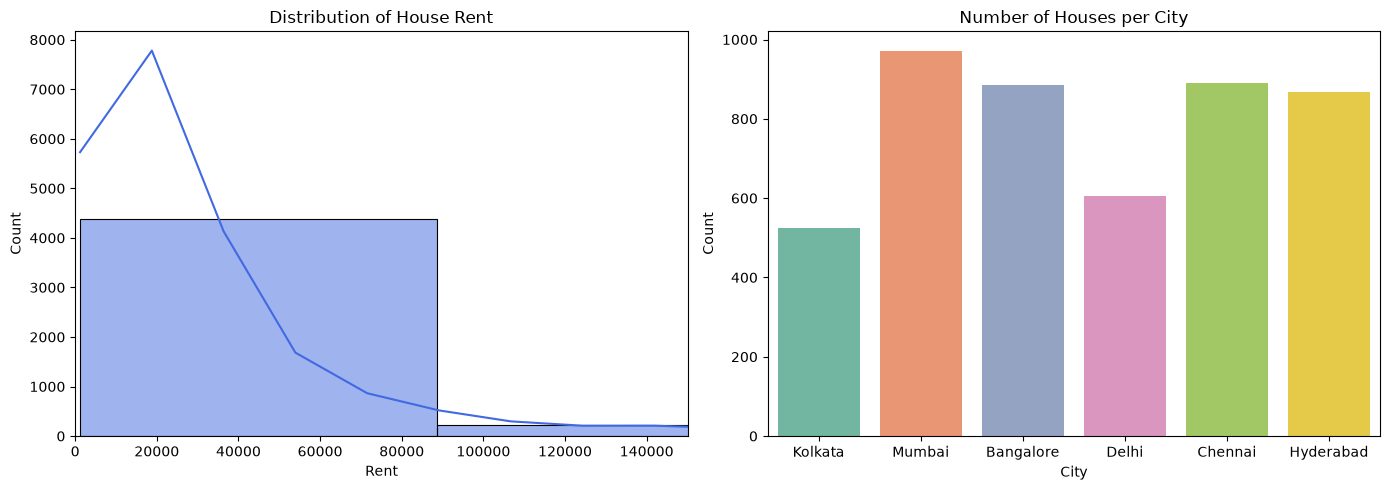

In [6]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Rent'], bins=40, kde=True, color='royalblue')
plt.title('Distribution of House Rent')
plt.xlabel('Rent')
plt.xlim(0, 150000)

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='City', palette='Set2')
plt.title('Number of Houses per City')
plt.xlabel('City')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [7]:
categorical_columns = ['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']

df_clean = df.copy()
label_encoders = {}

for col in categorical_columns:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col])
    label_encoders[col] = le

feature_columns = ['BHK', 'Size', 'Bathroom', 'Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']
X = df_clean[feature_columns]


print(feature_columns)
df_clean[feature_columns].head()

['BHK', 'Size', 'Bathroom', 'Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']


,BHK,Size,Bathroom,Area Type,City,Furnishing Status,Tenant Preferred,Point of Contact
0,2,1100.0,2.0,2,4,2,1,2
1,2,850.0,1.0,2,4,1,1,2
2,2,1000.0,1.0,2,4,1,1,2
3,2,850.0,1.0,2,4,2,1,2
4,2,850.0,1.0,1,4,2,0,2


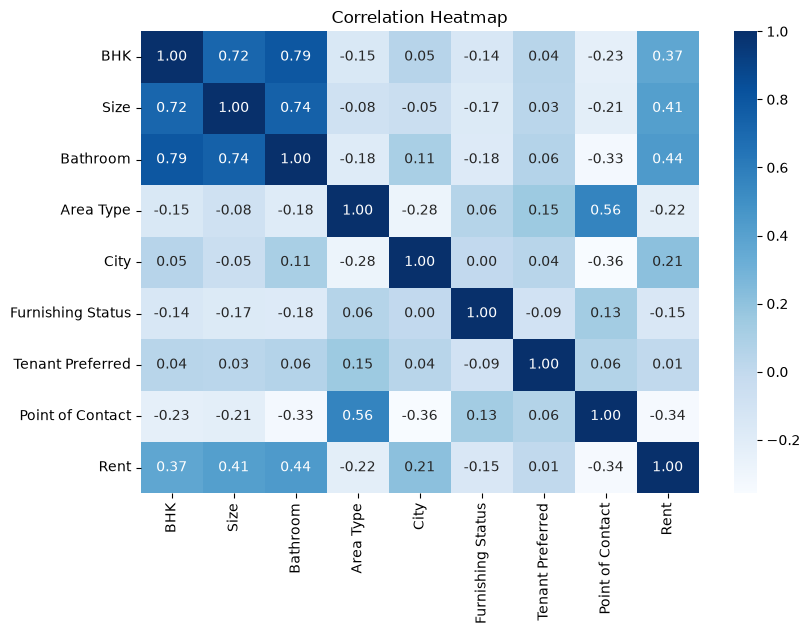

In [9]:
plt.figure(figsize=(9, 6))
sns.heatmap(df_clean[feature_columns + ['Rent']].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

---
# Part 1: Regression Task (Target: `Rent`)

**Why Regression?**
The target variable `Rent` is continuous. Regression models predict continuous numerical outcomes.

We apply:
1. **Linear Regression**
2. **K-Nearest Neighbors Regressor (KNN)**
3. **Support Vector Machine Regressor (SVR)**


In [11]:
y_reg = df_clean['Rent']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

scaler_r = StandardScaler()
X_train_r_scaled = scaler_r.fit_transform(X_train_r)
X_test_r_scaled = scaler_r.transform(X_test_r)

print(X_train_r.shape)

(3796, 8)


### 1.1 Linear Regression

In [12]:
lr_model = LinearRegression()
lr_model.fit(X_train_r_scaled, y_train_r)

y_pred_lr = lr_model.predict(X_test_r_scaled)

mae_lr = mean_absolute_error(y_test_r, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test_r, y_pred_lr))
r2_lr = r2_score(y_test_r, y_pred_lr)

print(f"MAE  : {mae_lr:.2f}")
print(f"RMSE : {rmse_lr:.2f}")
print(f"R²   : {r2_lr:.4f}")

MAE  : 23416.00
RMSE : 46444.40
R²   : 0.4587


### 1.2 K-Nearest Neighbors Regressor (KNN)

In [13]:
knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train_r_scaled, y_train_r)

y_pred_knn_r = knn_reg.predict(X_test_r_scaled)

mae_knn_r = mean_absolute_error(y_test_r, y_pred_knn_r)
rmse_knn_r = np.sqrt(mean_squared_error(y_test_r, y_pred_knn_r))
r2_knn_r = r2_score(y_test_r, y_pred_knn_r)

print(f"MAE  : {mae_knn_r:.2f}")
print(f"RMSE : {rmse_knn_r:.2f}")
print(f"R²   : {r2_knn_r:.4f}")

MAE  : 14745.96
RMSE : 48500.34
R²   : 0.4097


### 1.3 Support Vector Regressor (SVR)

In [14]:
svr_model = SVR(kernel='rbf', C=1000)
svr_model.fit(X_train_r_scaled, y_train_r)

y_pred_svr = svr_model.predict(X_test_r_scaled)

mae_svr = mean_absolute_error(y_test_r, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test_r, y_pred_svr))
r2_svr = r2_score(y_test_r, y_pred_svr)

print(f"MAE  : {mae_svr:.2f}")
print(f"RMSE : {rmse_svr:.2f}")
print(f"R²   : {r2_svr:.4f}")

MAE  : 15447.18
RMSE : 53657.31
R²   : 0.2775


### Regression Models Comparison

C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_22040\1649576360.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=regression_results, x='Model', y='R² Score', palette='viridis')
C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_22040\1649576360.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=regression_results, x='Model', y='MAE', palette='magma')


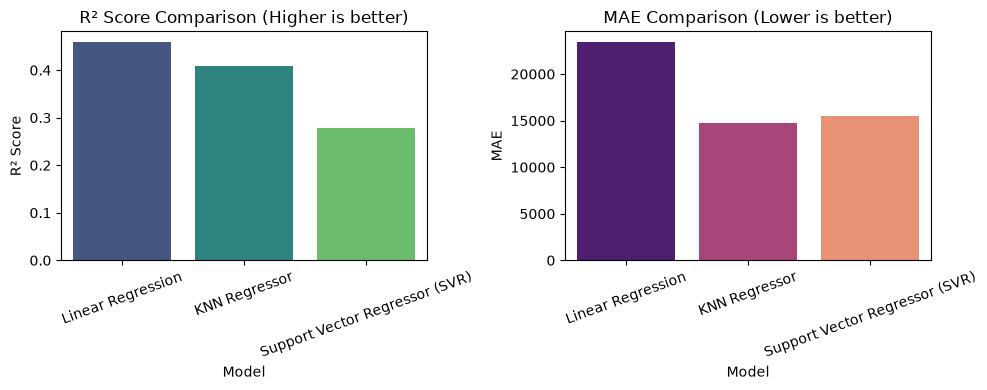

In [15]:
regression_results = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regressor', 'Support Vector Regressor (SVR)'],
    'MAE': [mae_lr, mae_knn_r, mae_svr],
    'RMSE': [rmse_lr, rmse_knn_r, rmse_svr],
    'R² Score': [r2_lr, r2_knn_r, r2_svr]
})


plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.barplot(data=regression_results, x='Model', y='R² Score', palette='viridis')
plt.title('R² Score Comparison (Higher is better)')
plt.xticks(rotation=20)

plt.subplot(1, 2, 2)
sns.barplot(data=regression_results, x='Model', y='MAE', palette='magma')
plt.title('MAE Comparison (Lower is better)')
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

---
# Part 2: Classification Task (Target: `Rent_Category`)

**Why Classification?**
To apply classification algorithms (Logistic Regression, Naive Bayes, KNN Classifier, SVM Classifier), we define a discrete target.
Here, we categorize rent into:
- **0**: Low / Affordable Rent (Rent <= median)
- **1**: High Rent (Rent > median)

We apply:
1. **Logistic Regression**
2. **K-Nearest Neighbors Classifier (KNN)**
3. **Naive Bayes (GaussianNB)**
4. **Support Vector Machine Classifier (SVC)**


In [17]:
median_rent = df_clean['Rent'].median()
df_clean['Rent_Category'] = (df_clean['Rent'] > median_rent).astype(int)


y_clf = df_clean['Rent_Category']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

print(X_train_c.shape)

(3796, 8)


### 2.1 Logistic Regression

In [18]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_c_scaled, y_train_c)

y_pred_log = log_reg.predict(X_test_c_scaled)

acc_log = accuracy_score(y_test_c, y_pred_log)
prec_log = precision_score(y_test_c, y_pred_log)
rec_log = recall_score(y_test_c, y_pred_log)
f1_log = f1_score(y_test_c, y_pred_log)

print(f" {acc_log:.4f}")
print(classification_report(y_test_c, y_pred_log))

 0.8179
              precision    recall  f1-score   support

           0       0.78      0.89      0.84       490
           1       0.87      0.74      0.80       460

    accuracy                           0.82       950
   macro avg       0.83      0.82      0.82       950
weighted avg       0.82      0.82      0.82       950



### 2.2 K-Nearest Neighbors Classifier (KNN)

In [19]:
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_c_scaled, y_train_c)

y_pred_knn_c = knn_clf.predict(X_test_c_scaled)

acc_knn_c = accuracy_score(y_test_c, y_pred_knn_c)
prec_knn_c = precision_score(y_test_c, y_pred_knn_c)
rec_knn_c = recall_score(y_test_c, y_pred_knn_c)
f1_knn_c = f1_score(y_test_c, y_pred_knn_c)

print(f"{acc_knn_c:.4f}")
print(classification_report(y_test_c, y_pred_knn_c))

0.8284
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       490
           1       0.84      0.79      0.82       460

    accuracy                           0.83       950
   macro avg       0.83      0.83      0.83       950
weighted avg       0.83      0.83      0.83       950



### 2.3 Naive Bayes (Gaussian Naive Bayes)

In [20]:
nb_clf = GaussianNB()
nb_clf.fit(X_train_c, y_train_c)

y_pred_nb = nb_clf.predict(X_test_c)

acc_nb = accuracy_score(y_test_c, y_pred_nb)
prec_nb = precision_score(y_test_c, y_pred_nb)
rec_nb = recall_score(y_test_c, y_pred_nb)
f1_nb = f1_score(y_test_c, y_pred_nb)

print(f"{acc_nb:.4f}")
print(classification_report(y_test_c, y_pred_nb))

0.8032
              precision    recall  f1-score   support

           0       0.78      0.86      0.82       490
           1       0.84      0.74      0.78       460

    accuracy                           0.80       950
   macro avg       0.81      0.80      0.80       950
weighted avg       0.81      0.80      0.80       950



### 2.4 Support Vector Machine Classifier (SVC)

In [21]:
svc_clf = SVC(kernel='rbf', C=1.0)
svc_clf.fit(X_train_c_scaled, y_train_c)

y_pred_svc = svc_clf.predict(X_test_c_scaled)

acc_svc = accuracy_score(y_test_c, y_pred_svc)
prec_svc = precision_score(y_test_c, y_pred_svc)
rec_svc = recall_score(y_test_c, y_pred_svc)
f1_svc = f1_score(y_test_c, y_pred_svc)

print(f"{acc_svc:.4f}")
print( classification_report(y_test_c, y_pred_svc))

0.8421
              precision    recall  f1-score   support

           0       0.82      0.89      0.85       490
           1       0.87      0.79      0.83       460

    accuracy                           0.84       950
   macro avg       0.84      0.84      0.84       950
weighted avg       0.84      0.84      0.84       950



### Classification Models Comparison & Confusion Matrices

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.817895   0.867008  0.736957  0.796710
1       KNN Classifier  0.828421   0.844548  0.791304  0.817059
2          Naive Bayes  0.803158   0.835381  0.739130  0.784314
3            SVM (SVC)  0.842105   0.869048  0.793478  0.829545


C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_22040\2060646290.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=classification_results, x='Model', y='Accuracy', palette='coolwarm')


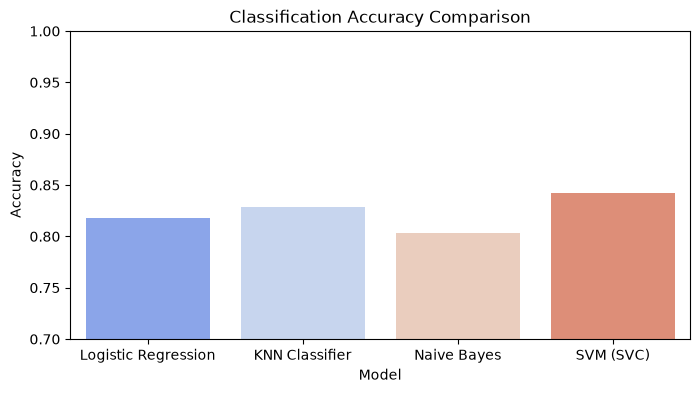

In [22]:
classification_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN Classifier', 'Naive Bayes', 'SVM (SVC)'],
    'Accuracy': [acc_log, acc_knn_c, acc_nb, acc_svc],
    'Precision': [prec_log, prec_knn_c, prec_nb, prec_svc],
    'Recall': [rec_log, rec_knn_c, rec_nb, rec_svc],
    'F1 Score': [f1_log, f1_knn_c, f1_nb, f1_svc]
})

print(classification_results)

plt.figure(figsize=(8, 4))
sns.barplot(data=classification_results, x='Model', y='Accuracy', palette='coolwarm')
plt.title('Classification Accuracy Comparison')
plt.ylim(0.7, 1.0)
plt.ylabel('Accuracy')
plt.show()

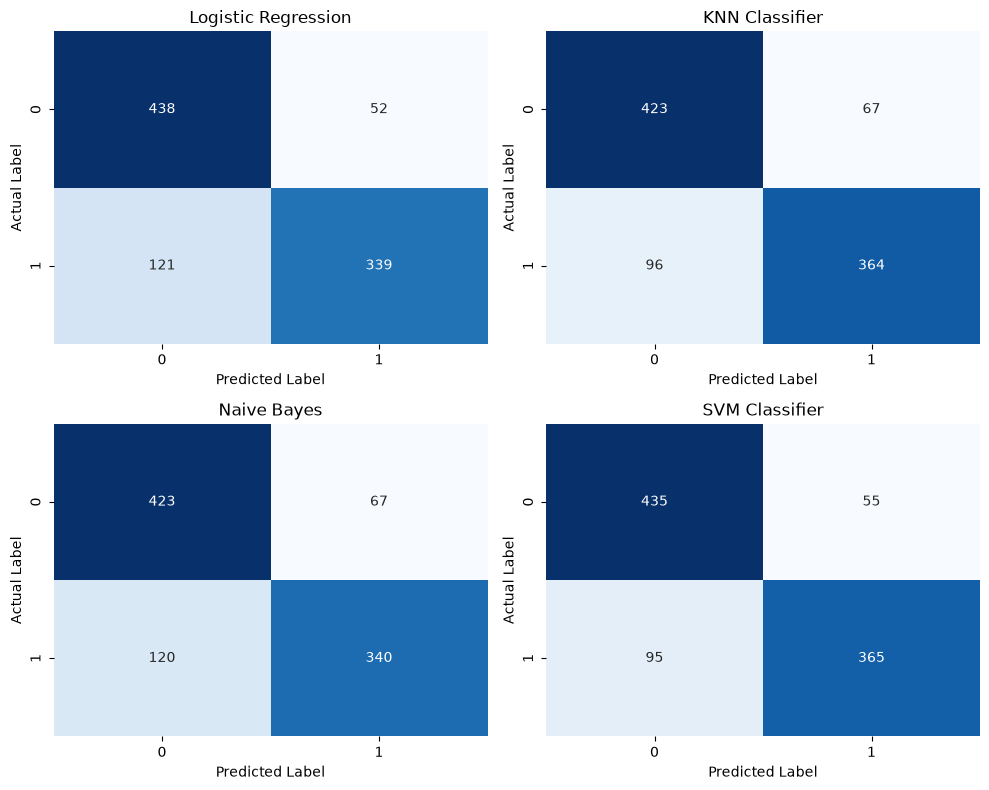

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

models_preds = [
    ('Logistic Regression', y_pred_log, axes[0, 0]),
    ('KNN Classifier', y_pred_knn_c, axes[0, 1]),
    ('Naive Bayes', y_pred_nb, axes[1, 0]),
    ('SVM Classifier', y_pred_svc, axes[1, 1])
]

for title, preds, ax in models_preds:
    cm = confusion_matrix(y_test_c, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

---
## 4. Final Summary and Conclusions

### Summary of Models Applied:
1. **Regression Models (Continuous Target: `Rent`)**:
   - **Linear Regression**: Fast, interpretable baseline; assumes linear relationships.
   - **KNN Regressor**: Non-parametric, distance-based algorithm; predicts based on nearest neighbors.
   - **Support Vector Regressor (SVR)**: Uses hyperplane with margin tolerance (epsilon); handles non-linear relationships via RBF kernel.

2. **Classification Models (Categorical Target: `Rent_Category`)**:
   - **Logistic Regression**: Linear boundary classifier modeling probabilities with sigmoid function.
   - **KNN Classifier**: Classifies based on majority vote of $k$ closest neighbors.
   - **Naive Bayes**: Probabilistic classifier applying Bayes theorem under feature independence assumption.
   - **SVM Classifier (SVC)**: Finds the maximum-margin hyperplane separating classes, with RBF kernel for non-linear boundaries.

### Key Takeaways:
- **Data Scaling (`StandardScaler`)** is critical for distance-sensitive algorithms like **KNN** and **SVM**.
- When the target is continuous (`Rent`), we use **Regression**.
- When the target is discrete or categorized (`Rent_Category`), we use **Classification**.
